# Indoor Location Prediction: Exploratory Data Analysis (EDA)
**Project 9 · CSAI Student Project · Phase 1: Machine Learning Evaluation**

## 1. Executive Summary & Objective
Indoor positioning is a challenging spatial regression and multi-class classification problem because GPS signals attenuate significantly inside buildings. This notebook performs a comprehensive exploratory audit of the **UJIIndoorLoc** dataset, collected across three multi-story buildings at Universitat Jaume I.

### Key EDA Questions:
1. What is the spatial distribution of fingerprint collection points across Buildings and Floors?
2. How sparse are the Wireless Access Point (WAP) RSSI observations, and what does the  missing signal artifact represent?
3. How many APs are active per fingerprint scan, and which APs provide zero information variance?
4. How do user devices () and collectors () differ between training and validation data, and what are the implications for generalization?


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print('Environment setup complete.')


Environment setup complete.


## 2. Dataset Ingestion and Schema Audit
We load both  and  from .


In [2]:
train_path = '../Datasets/UJIndoorLoc/trainingData.csv'
val_path = '../Datasets/UJIndoorLoc/validationData.csv'

if not os.path.exists(train_path):
    train_path = 'Datasets/UJIndoorLoc/trainingData.csv'
    val_path = 'Datasets/UJIndoorLoc/validationData.csv'

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)

print(f'Training shape:   {train_df.shape[0]:,} rows x {train_df.shape[1]} columns')
print(f'Validation shape: {val_df.shape[0]:,} rows x {val_df.shape[1]} columns')

wap_cols = [c for c in train_df.columns if c.startswith('WAP')]
meta_cols = [c for c in train_df.columns if not c.startswith('WAP')]

print(f'Total WAP columns: {len(wap_cols)}')
print('Metadata attributes:', meta_cols)


Training shape:   19,937 rows x 529 columns
Validation shape: 1,111 rows x 529 columns
Total WAP columns: 520
Metadata attributes: ['LONGITUDE', 'LATITUDE', 'FLOOR', 'BUILDINGID', 'SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']


## 3. Spatial Distribution & Floor Plans
We examine the 2D footprint (Longitude vs Latitude) colored by Building ID and Floor level.


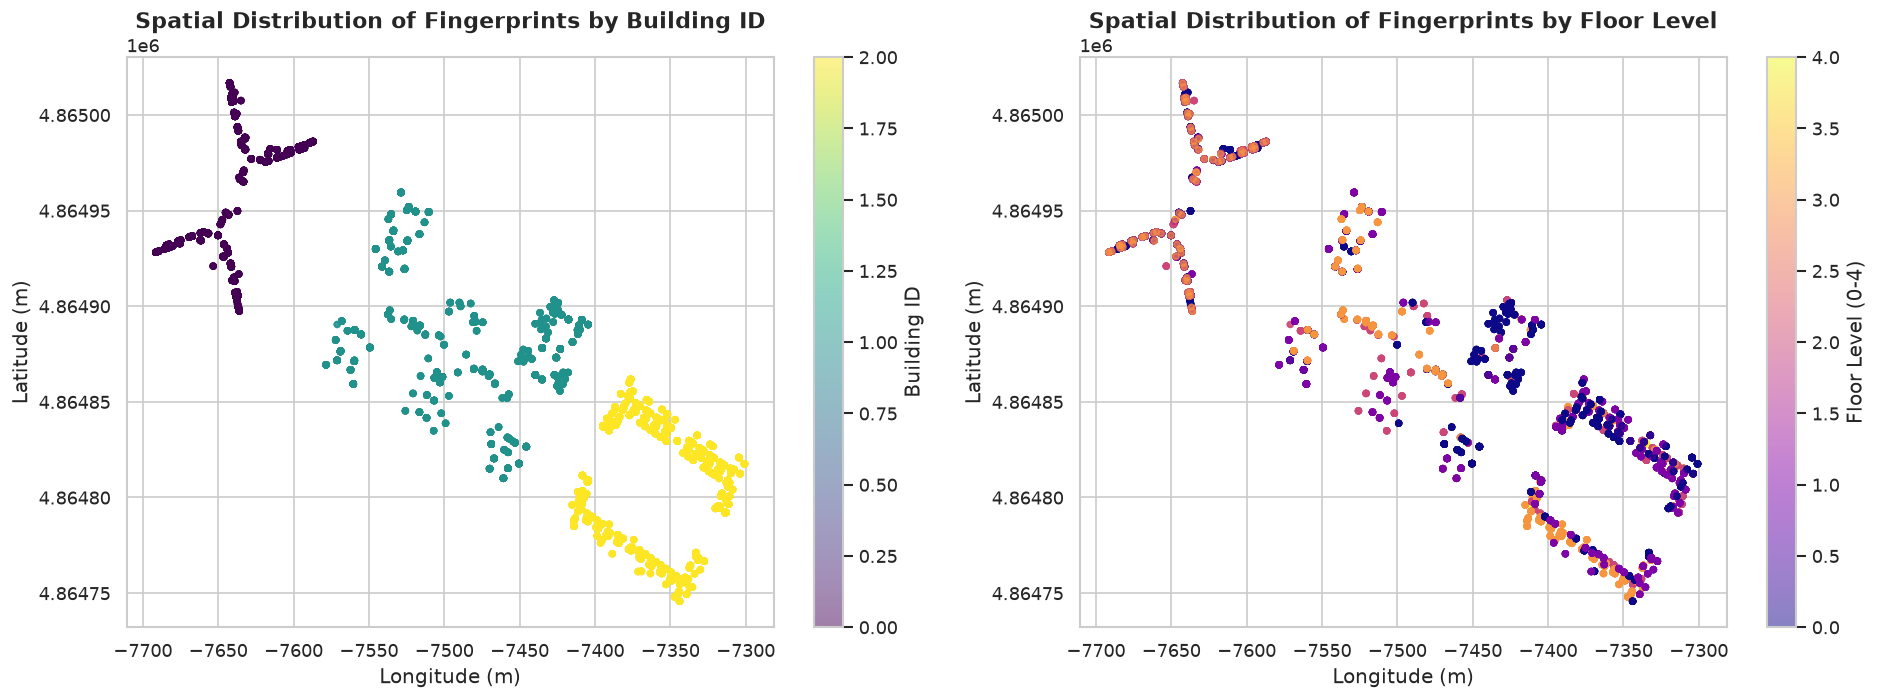

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

scatter1 = axes[0].scatter(train_df['LONGITUDE'], train_df['LATITUDE'], c=train_df['BUILDINGID'], cmap='viridis', alpha=0.5, s=12)
axes[0].set_title('Spatial Distribution of Fingerprints by Building ID', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Longitude (m)')
axes[0].set_ylabel('Latitude (m)')
cbar1 = plt.colorbar(scatter1, ax=axes[0])
cbar1.set_label('Building ID')

scatter2 = axes[1].scatter(train_df['LONGITUDE'], train_df['LATITUDE'], c=train_df['FLOOR'], cmap='plasma', alpha=0.5, s=12)
axes[1].set_title('Spatial Distribution of Fingerprints by Floor Level', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Longitude (m)')
axes[1].set_ylabel('Latitude (m)')
cbar2 = plt.colorbar(scatter2, ax=axes[1])
cbar2.set_label('Floor Level (0-4)')

plt.tight_layout()
os.makedirs('../figures', exist_ok=True) if os.path.exists('../figures') else os.makedirs('figures', exist_ok=True)
fig_dir = '../figures' if os.path.exists('../figures') else 'figures'
plt.savefig(f'{fig_dir}/spatial_distribution.png', dpi=200, bbox_inches='tight')
plt.show()


## 4. Class Distribution: Buildings and Floors
Inspection of class imbalance across the 3 buildings and 5 floors in both training and validation splits.


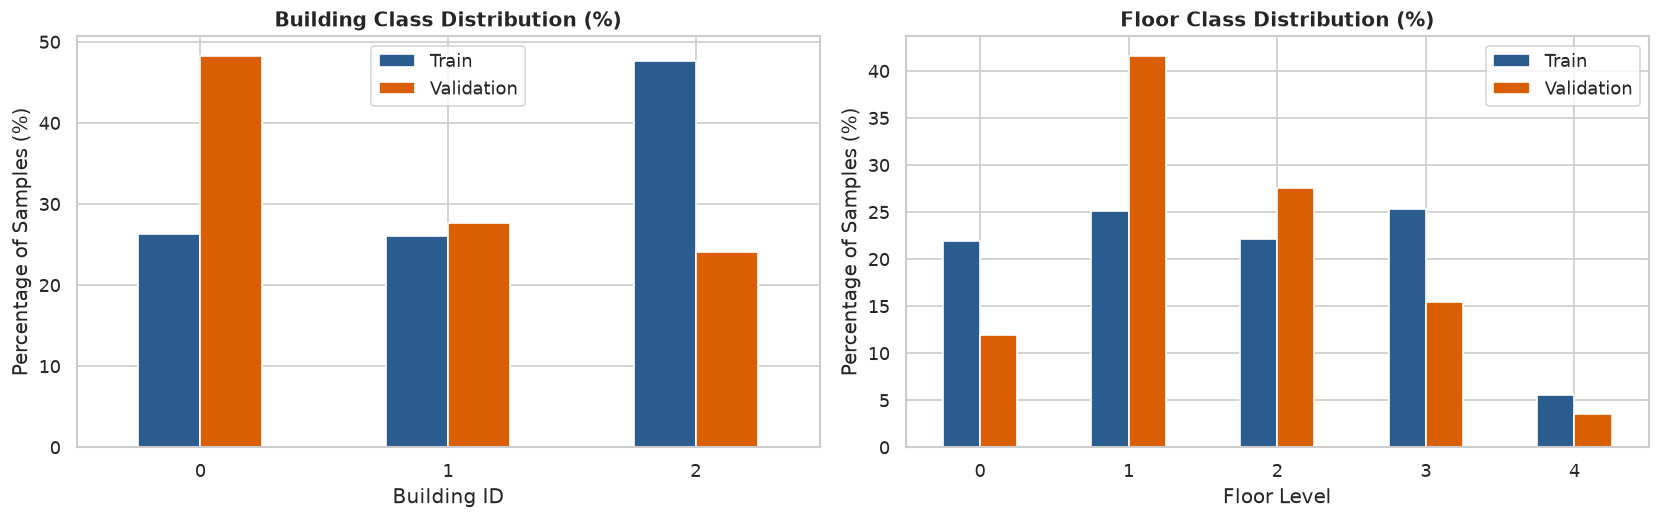

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

bldg_comp = pd.DataFrame({
    'Train': train_df['BUILDINGID'].value_counts(normalize=True) * 100,
    'Validation': val_df['BUILDINGID'].value_counts(normalize=True) * 100
})
bldg_comp.plot(kind='bar', ax=axes[0], rot=0, color=['#2b5c8f', '#d95f02'])
axes[0].set_title('Building Class Distribution (%)', fontweight='bold')
axes[0].set_xlabel('Building ID')
axes[0].set_ylabel('Percentage of Samples (%)')

floor_comp = pd.DataFrame({
    'Train': train_df['FLOOR'].value_counts(normalize=True) * 100,
    'Validation': val_df['FLOOR'].value_counts(normalize=True) * 100
}).sort_index()
floor_comp.plot(kind='bar', ax=axes[1], rot=0, color=['#2b5c8f', '#d95f02'])
axes[1].set_title('Floor Class Distribution (%)', fontweight='bold')
axes[1].set_xlabel('Floor Level')
axes[1].set_ylabel('Percentage of Samples (%)')

plt.tight_layout()
plt.savefig(f'{fig_dir}/class_distribution.png', dpi=200, bbox_inches='tight')
plt.show()


## 5. Wi-Fi Signal Sparsity & Missing Value Artifacts ( dBm)
In UJIIndoorLoc:
- Observed RSSI values range from  (very weak) to  (strong).
- A value of  is an encoding convention indicating that the WAP was **not detected** during that scan.


Overall dataset sparsity (unobserved signals): 96.54%


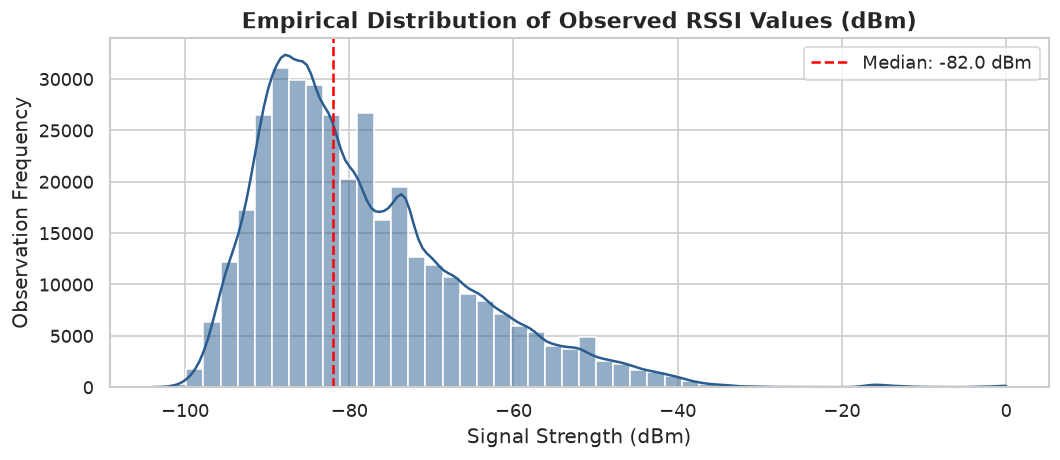

In [5]:
train_waps = train_df[wap_cols]
sparsity = (train_waps == 100).mean().mean() * 100
print(f'Overall dataset sparsity (unobserved signals): {sparsity:.2f}%')

# Observed signals only
detected_signals = train_waps.values[train_waps.values != 100]

plt.figure(figsize=(9, 4))
sns.histplot(detected_signals, bins=50, kde=True, color='#2b5c8f')
plt.title('Empirical Distribution of Observed RSSI Values (dBm)', fontsize=13, fontweight='bold')
plt.xlabel('Signal Strength (dBm)')
plt.ylabel('Observation Frequency')
plt.axvline(np.median(detected_signals), color='red', linestyle='--', label=f'Median: {np.median(detected_signals):.1f} dBm')
plt.legend()
plt.tight_layout()
plt.savefig(f'{fig_dir}/rssi_distribution.png', dpi=200, bbox_inches='tight')
plt.show()


## 6. Access Point Visibility & Zero-Variance Filtering
We calculate how many WAPs are detected per scan, and find WAPs that never detect any signal in the entire dataset.


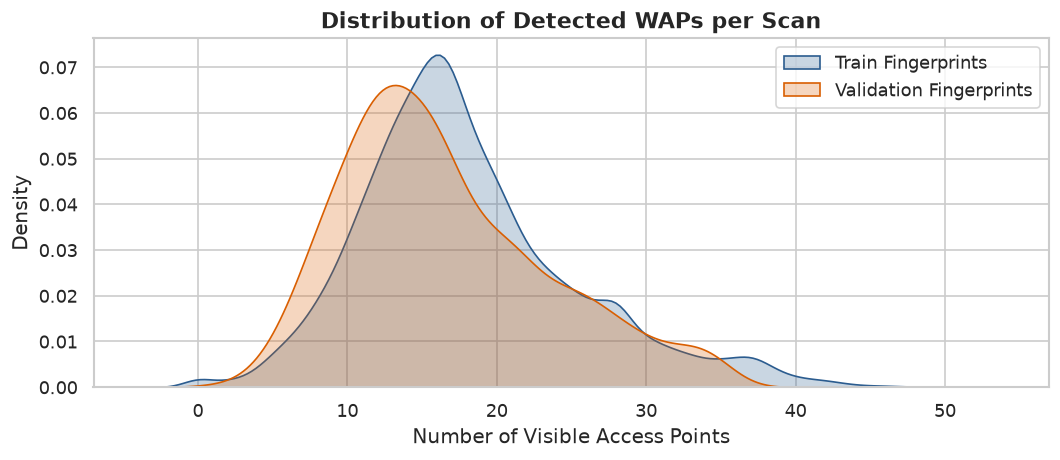

Dead WAPs (100% undetected in train): 55 out of 520
Empty scans (0 APs visible) in training set: 76


In [6]:
train_detected_count = (train_waps != 100).sum(axis=1)
val_detected_count = (val_df[wap_cols] != 100).sum(axis=1)

fig, ax = plt.subplots(figsize=(9, 4))
sns.kdeplot(train_detected_count, label='Train Fingerprints', fill=True, color='#2b5c8f', ax=ax)
sns.kdeplot(val_detected_count, label='Validation Fingerprints', fill=True, color='#d95f02', ax=ax)
ax.set_title('Distribution of Detected WAPs per Scan', fontsize=13, fontweight='bold')
ax.set_xlabel('Number of Visible Access Points')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.savefig(f'{fig_dir}/ap_visibility_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

# Detect uninformative WAPs
zero_var_waps = [w for w in wap_cols if (train_waps[w] == 100).all()]
print(f'Dead WAPs (100% undetected in train): {len(zero_var_waps)} out of {len(wap_cols)}')
empty_scans = (train_detected_count == 0).sum()
print(f'Empty scans (0 APs visible) in training set: {empty_scans}')


## 7. User and Device Domain Shift Audit
In real-world Wi-Fi positioning, different antenna chipsets measure RSSI differently. We audit  and  across splits.


In [7]:
phone_train = train_df['PHONEID'].value_counts()
phone_val = val_df['PHONEID'].value_counts()

print('Phone IDs in Training:', len(phone_train), 'distinct devices')
print('Phone IDs in Validation:', len(phone_val), 'distinct devices')
print('Common Phone IDs:', len(set(phone_train.index).intersection(set(phone_val.index))))
print('Users in Training:', train_df['USERID'].nunique(), 'distinct users')
print('Users in Validation:', val_df['USERID'].nunique(), 'distinct users')


Phone IDs in Training: 16 distinct devices
Phone IDs in Validation: 11 distinct devices
Common Phone IDs: 2
Users in Training: 18 distinct users
Users in Validation: 1 distinct users


## 8. Summary of EDA Findings & Preprocessing Decisions
1. **Missing Convention**: The  artifact must be mapped to an absent baseline (e.g. ) and normalized to 1$ so zero corresponds to signal absence.
2. **Dead Feature Pruning**: 55 WAPs never detect any signal in training data and must be removed to avoid zero-variance noise.
3. **Empty Scan Removal**: 76 training scans contain 0 visible APs and must be pruned.
4. **Engineered Predictors**: Total signal count (), maximum visible signal (), and mean visible signal () provide strong physical proxies for distance to nearest access points.
5. **Generalization Gap**: Validation data is collected with distinct devices and users, replicating realistic field performance.
